# TP2 : Extraction d'information

Corpus : CAMille

Année choisie : 1949

## Préparation des données



### Imports

In [221]:
import os


### Choix de l'année et vérification de l'accès aux fichiers

In [ ]:

# Choix de l'année
year = 1949

# Chemin vers les fichiers texte 
txt_path = '../../data/txt'

# Vérifier le nombre de fichiers
print(len([f for f in os.listdir(txt_path) if f.endswith('.txt')]), "fichiers .txt dans le corpus")

7936 fichiers .txt dans le corpus


In [223]:
# Liste des fichiers de 1949
txts = [f for f in os.listdir(txt_path) if os.path.isfile(os.path.join(txt_path, f)) and str(year) in f]
len(txts)

100

## Mots-clés


### Imports

In [224]:
import yake

### Essai avec 1 fichier

In [225]:
# Instantier l'extracteur de mots clés
kw_extractor = yake.KeywordExtractor(lan="fr", top=50)
kw_extractor

In [226]:
# Choisir un fichier
this_file = txts[0]
this_file

# Récupérer le texte du fichier
text = open(os.path.join(txt_path, this_file), 'r', encoding='utf-8').read()
text[:500]

"63* ANNEE — N° 2 ». •’•» ÏOUBNAL QUOTIDIEN 4 Pages-Iir.25 France: 13 fr. franç. —> Suisse: 0 fr. 35 suisse CHEQUES POSTAUX : PUBLICITE : Compte n* 5675 Boesèl & C u VENTE : Soir et Soir Illustré : 14686 Bossel et C 1 * DONS aux Œuvres du Soir : 14232 Bossel et C* Les maaascrits non insérés ne sont pas rendus SEDUCTION t 21. PLACE UE LOUVAIN, 21 VENTE ET ABONN. : PLACE DE LOUVAIN, 23 ANNONCÉS î AG. 'BOSSEL. BUE BOYALE, 122 SALLE DE DEPECHES ! RUE BOYALE, 124 — BRUXELLES BUREAUX : PARIS. 10, rue d"

In [227]:
# Extraire les mots clés de ce texte
keywords = kw_extractor.extract_keywords(text)
keywords

[('Tell Aviv', np.float64(0.006229628843759752)),
 ('Janvier', np.float64(0.010285336338878272)),
 ('gouvernement', np.float64(0.015229444000799291)),
 ('Soir', np.float64(0.018597459525415912)),
 ('Aviv', np.float64(0.020684234303065048)),
 ('LONDRES', np.float64(0.021634737039558125)),
 ('Caire Tell Aviv', np.float64(0.0231510758028533)),
 ('Tell', np.float64(0.02550047756906971)),
 ('nuit', np.float64(0.02913440922340206)),
 ('paix', np.float64(0.029996758248772484)),
 ('suisse CHEQUES POSTAUX', np.float64(0.033714106680947924)),
 ('sterling', np.float64(0.03497351840899521)),
 ('Nouvel', np.float64(0.03755047932709011)),
 ('ÏOUBNAL QUOTIDIEN', np.float64(0.03926587414064502)),
 ('l’année', np.float64(0.040500354344414576)),
 ('d’un', np.float64(0.0405329240829189)),
 ('guerre', np.float64(0.04690225045756586)),
 ('Reuter', np.float64(0.04893471063223419)),
 ('cours', np.float64(0.04934015651147171)),
 ('marchés', np.float64(0.05109886318657488)),
 ('déclaré', np.float64(0.055389683

In [228]:
# Ne garder que les bigrammes
kept = []
for kw, score in keywords:
    words = kw.split()
    if len(words) == 2:
        kept.append(kw)
kept

['Tell Aviv',
 'ÏOUBNAL QUOTIDIEN',
 'samedi soir',
 'Richard Berchard',
 'd’autre part',
 'vendredi soir',
 'Soir Illustré']

### Avec tous les fichiers sur 1949

#### Mots-clés fichier par fichier

In [229]:
# Pour tous les fichiers
for f in sorted(txts):
    text = open(os.path.join(txt_path, f), 'r', encoding="utf-8").read()
    keywords = kw_extractor.extract_keywords(text)
    kept = []
    for kw, score in keywords:
        words = kw.split()
        if len(words) == 2:
            kept.append(kw)
    print(f"{f} mentions these keywords: {', '.join(kept)}...")

KB_JB838_1949-01-03_01-00001.txt mentions these keywords: Tell Aviv, ÏOUBNAL QUOTIDIEN, samedi soir, Richard Berchard, d’autre part, vendredi soir, Soir Illustré...
KB_JB838_1949-01-06_01-00012.txt mentions these keywords: AGENCE ROSSEL, l’AGENCE ROSSEL, Ecrire Agence, Faire offre, Ecrire Ag.Rossel, Bruxelles dem, Bruxelles cherche, BRUXELLES demande, FIRME IMPORTANTE, cherche place, Demande REPRESENTANTS...
KB_JB838_1949-01-11_01-00008.txt mentions these keywords: BLANCHEUR NATURELLE, SAVONNERIES LEVER, LEVER FRERES, SUNLIGHT Assure, Agence Rossel, Rue Royale, mais. rent, Office Propriétaires, LOUER Maison, SOIR SUNLIGHT, maison rentier, CINEMAS ABC...
KB_JB838_1949-01-13_01-00002.txt mentions these keywords: Eve Francis, qu’Eve Francis, Temps héroïques, théâtre Eve, Jean Giraudoux, d’Eve Francis...
KB_JB838_1949-01-18_01-00008.txt mentions these keywords: Agence Rossel, rue Royale, Bruxelles Tél, louer maison, Forest Tél, Libre Bruxelles...
KB_JB838_1949-01-19_01-00006.txt mentions t

#### Mots-clés de toute l'année

In [230]:
# Stocker le contenu de ces fichiers dans une liste
content_list = []
for txt in txts:
    with open(os.path.join(txt_path, txt), 'r', encoding='utf-8') as f:
        content_list.append(f.read())

In [231]:
# Texte de toute l'année 1949
text = ' '.join(content_list)
len(text)

3852678

In [232]:
# Compter le nombre de fichiers
len(content_list)

100

In [233]:
# Ecrire tout le contenu dans un fichier temporaire
temp_path = '../../data/tmp'
if not os.path.exists(temp_path):
    os.mkdir(temp_path)
with open(os.path.join(temp_path, f'{year}.txt'), 'w', encoding='utf-8') as f:
    f.write(' '.join(content_list))

In [234]:
# Imprimer le contenu du fichier et constater les "déchets"
with open(os.path.join(temp_path, f'{year}.txt'), 'r', encoding='utf-8') as f:
    before = f.read()

before[:500]

"63* ANNEE — N° 2 ». •’•» ÏOUBNAL QUOTIDIEN 4 Pages-Iir.25 France: 13 fr. franç. —> Suisse: 0 fr. 35 suisse CHEQUES POSTAUX : PUBLICITE : Compte n* 5675 Boesèl & C u VENTE : Soir et Soir Illustré : 14686 Bossel et C 1 * DONS aux Œuvres du Soir : 14232 Bossel et C* Les maaascrits non insérés ne sont pas rendus SEDUCTION t 21. PLACE UE LOUVAIN, 21 VENTE ET ABONN. : PLACE DE LOUVAIN, 23 ANNONCÉS î AG. 'BOSSEL. BUE BOYALE, 122 SALLE DE DEPECHES ! RUE BOYALE, 124 — BRUXELLES BUREAUX : PARIS. 10, rue d"

In [235]:
# Extraire les mots clés de l'année
keywords = kw_extractor.extract_keywords(text)
keywords

[('Ecrire Agence Rossel', np.float64(2.261066648225967e-06)),
 ('Tél', np.float64(1.0833137522598043e-05)),
 ('BRUXELLES', np.float64(1.2684507784543877e-05)),
 ('ROSSEL RUE ROYALE', np.float64(1.4225930922201833e-05)),
 ('Bruxelles Tél', np.float64(1.5493171256141913e-05)),
 ('RUE', np.float64(1.6104020486656436e-05)),
 ('Bruxelles Anvers Tél', np.float64(1.862601393474564e-05)),
 ('Van', np.float64(2.0797379924040945e-05)),
 ('AGENCE ROSSEL', np.float64(2.4679269201129902e-05)),
 ('rue Van', np.float64(2.517757276892938e-05)),
 ('Rossel', np.float64(2.5615086812851847e-05)),
 ('MAISON BELGE Tél', np.float64(2.7630619147506696e-05)),
 ('prix', np.float64(3.124477364157428e-05)),
 ('RUE ROYALE', np.float64(3.253093137848506e-05)),
 ('prix Agence Rossel', np.float64(3.522757022409938e-05)),
 ('rue Royale Bruxelles', np.float64(4.1563836533663413e-05)),
 ('BRUXELLES MAISON BELGE', np.float64(4.567932185666841e-05)),
 ('AGENCE ROSSEL Bruxelles', np.float64(5.0687698642311833e-05)),
 ('gra

## Nuage de mots


### Imports

In [236]:
from collections import Counter
from wordcloud import WordCloud
import nltk
nltk.download('stopwords')
from nltk.corpus import stopwords
from IPython.display import Image

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\olivi\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


### Liste des mots vides

In [237]:
sw = stopwords.words("french")
sw += ["les", "plus", "cette", "fait", "faire", "être", "deux", "comme", "dont", "tout",
       "ils", "bien", "sans", "peut", "tous", "après", "ainsi", "donc", "cet", "sous",
       "celle", "entre", "encore", "toutes", "pendant", "moins", "dire", "cela", "non",
       "faut", "trois", "aussi", "dit", "avoir", "doit", "contre", "depuis", "autres",
       "van", "het", "autre", "jusqu", "ville", "rossel", "dem"]
# mots vides ajoutés avec chaque itération
sw += ["tél", "rue", "bruxelles", "prix", "ans", "ecr", "ecrire", "app", "bon", "très"]
sw += ["grand", "brux", "maison", "part", "place", "libre", "louer", "mois", "soir"]
sw += ["leurs", "peu", "mod", "heures", "saint", "belgique", "belge",]
sw += ["conf", "cuis", "bat", "bel", "demande", "vendre", "agence", "lieu", "etc",
       "cours", "avant", "mme", "bonne", "belle", "jour", "première", "toute", "temps"]
sw += ["vente", "vend", "pers", "eau", "vue", "centre", "francs",
       "quelques", "partie", "chez", "fin", "point", "ordre", "juillet", "juin"]
sw += ["cherche", "neuf", "pet", "avenue", "appart", "midi", "dimanche", "mai",
       "suite", "fois", "beau", "devant", "vers","car"]
sw += ["grande"]

sw = set(sw)

### Nettoyage

In [238]:
# Créer la fonction de nettoyage
def clean_text(year, folder=None):
    if folder is None:
        input_path = f"{year}.txt"
        output_path = f"{year}_clean.txt"
    else:
        input_path = f"{folder}/{year}.txt"
        output_path = f"{folder}/{year}_clean.txt"
    output = open(output_path, "w", encoding='utf-8')
    with open(input_path, 'r', encoding='utf-8') as f:
        text = f.read()
        words = nltk.wordpunct_tokenize(text)
        kept = [w.upper() for w in words if len(w) > 2 and w.isalpha() and w.lower() not in sw]
        kept_string = " ".join(kept)
        output.write(kept_string)
    return f'Output has been written in {output_path}!'

In [239]:
# Appliquer la fonction
clean_text(year, folder=temp_path)


'Output has been written in ../../data/tmp/1949_clean.txt!'

In [240]:
# Vérifier le résultat
with open(os.path.join(temp_path, f'{year}_clean.txt'), 'r', encoding='utf-8') as f:
    after = f.read()

after[:500]

'ANNEE ÏOUBNAL QUOTIDIEN PAGES IIR FRANCE FRANÇ SUISSE SUISSE CHEQUES POSTAUX PUBLICITE COMPTE BOESÈL ILLUSTRÉ BOSSEL DONS ŒUVRES BOSSEL MAAASCRITS INSÉRÉS RENDUS SEDUCTION LOUVAIN ABONN LOUVAIN ANNONCÉS BOSSEL BUE BOYALE SALLE DEPECHES BOYALE BUREAUX PARIS BOURSE LONDRES OLIICE QUEEN VICTORIA STREET LONDON NEW YORK AUSTIN STREET FOROST HILLS ZURICH MÜHLEBDCHSTRASSE HCK PTEŒLÈTE DEUXIÈME VJR TÏBIRFÈME QUATRIÈME ÉDIT EDITION NUIT ÉDIT NUI LUNDI JANVIER TELEPHONES ÉDITION LIGNE QUELLE HEURE LAQUELL'

### Création du nuage

In [241]:
frequencies = Counter(after.split())
print(frequencies.most_common(25))

[('PAYS', 421), ('ÉTAT', 400), ('FRANCE', 357), ('ANVERS', 349), ('DIVISION', 315), ('PREMIER', 290), ('PARIS', 287), ('MINISTRE', 280), ('FRANÇAIS', 279), ('GÉNÉRAL', 272), ('LOUISE', 268), ('ETAT', 265), ('LOI', 257), ('DAME', 253), ('PRÉSIDENT', 249), ('TRAVAIL', 249), ('VIS', 247), ('UNION', 245), ('TOUR', 241), ('NORD', 240), ('SERVICE', 240), ('VILLA', 238), ('CHAMBRE', 231), ('GUERRE', 230), ('TÉLÉPH', 230)]


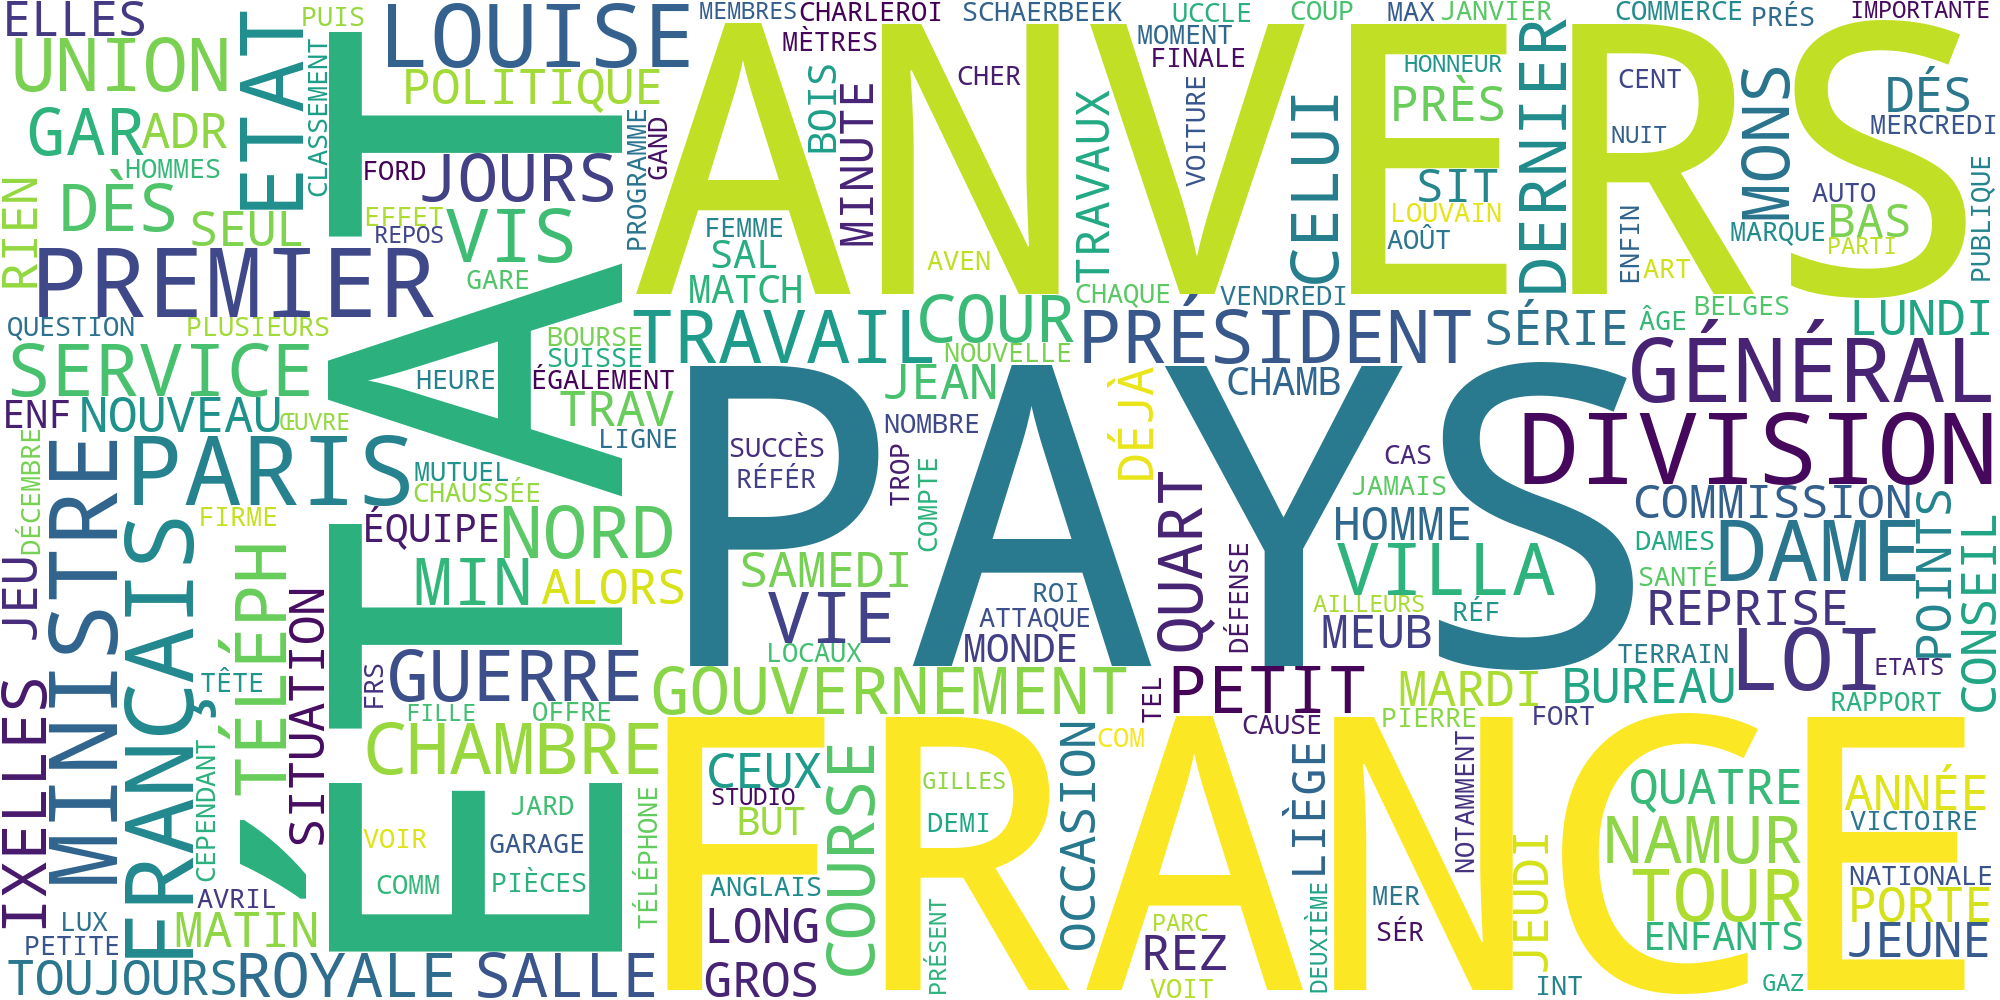

In [242]:
cloud = WordCloud(width=2000, height=1000, background_color='white').generate_from_frequencies(frequencies)
cloud.to_file(os.path.join(temp_path, f"{year}.png"))
Image(filename=os.path.join(temp_path, f"{year}.png"))

## Les entités nommées


### Imports

In [243]:
from collections import defaultdict
import spacy

In [244]:
nlp = spacy.load('fr_core_news_md')

### Sur 1 fichier

In [245]:
# Tester sur un fichier
text = open(os.path.join(txt_path, txts[0]), 'r', encoding='utf-8').read()
doc = nlp(text)

for ent in doc.ents[:15]:
    print(f"{ent.text} ({ent.label_})")

N (LOC)
franç (LOC)
Suisse (LOC)
suisse (LOC)
POSTAUX (MISC)
Boesèl & C (MISC)
Soir (MISC)
Soir Illustré (MISC)
Bossel (LOC)
C (MISC)
Œuvres du Soir (MISC)
Bossel (LOC)
C (LOC)
PLACE UE LOUVAIN (ORG)
VENTE (MISC)


### Sur tous les fichiers de 1949

In [246]:
%%time
# Compter les entités
people = defaultdict(int)
orgs = defaultdict(int)
places = defaultdict(int)

# Compter les entités, un fichier à la fois 
for f in sorted(txts):
    text = open(os.path.join(txt_path, f), 'r', encoding='utf-8').read()
    doc = nlp(text)
    for ent in doc.ents:
        if ent.label_ == "PER" and len(ent.text) > 3:
            people[ent.text] += 1
        if ent.label_ == "ORG" and len(ent.text) > 3:
            orgs[ent.text] += 1
        if ent.label_ == "LOC" and len(ent.text) > 3:
            places[ent.text] += 1

CPU times: total: 1min 56s
Wall time: 2min 1s


### Liste pour réduire le bruit

In [ ]:
# Entités écartées : termes d'annonces, abréviations d'OCR, termes trop génériques
bruit_personnes = {"Agence Rossel", "Ecrire Ag", "- Tél", "trav", "Inut", "Louise",
                   "Monsieur", "Bonne", "chamb", "atel", "s.d.b", "coch", "A.F.P.", "Mutuel", "Pronostics"}
bruit_orgs = {"Mutuel", "Pronostics", "CREDIT", "Téléphone", "Quatrième course", "K ON DEM"}
bruit_places = {"Téléph", "Etat","état"}

### Personnes

In [248]:
# Trier et imprimer
sorted_people = sorted(people.items(), key=lambda kv: kv[1], reverse=True)

for person, freq in sorted_people[:50]:
    if person not in bruit_personnes:
        print(f"{person} apparait {freq} fois en 1949")

Régent apparait 33 fois en 1949
Joseph apparait 27 fois en 1949
Léopold apparait 25 fois en 1949
Mutuel apparait 25 fois en 1949
Brugmann apparait 24 fois en 1949
Janssens apparait 24 fois en 1949
P. S. C. apparait 22 fois en 1949
Pronostics apparait 22 fois en 1949
Molière apparait 21 fois en 1949
Hitler apparait 20 fois en 1949
Mozart apparait 20 fois en 1949
Staline apparait 20 fois en 1949
Daring apparait 19 fois en 1949
jard apparait 18 fois en 1949
Albert apparait 18 fois en 1949
Washer apparait 18 fois en 1949
Gros apparait 18 fois en 1949
Jette apparait 17 fois en 1949
Ec Ag apparait 17 fois en 1949
Bach apparait 17 fois en 1949
Beethoven apparait 17 fois en 1949
Pauwels apparait 17 fois en 1949
Holl apparait 17 fois en 1949
M. Van Cauwelaert apparait 17 fois en 1949
Hellas apparait 16 fois en 1949
Mindszenty apparait 16 fois en 1949
Herman apparait 16 fois en 1949
Linssen apparait 16 fois en 1949
CHERC apparait 15 fois en 1949
M. Schuman apparait 15 fois en 1949
Jacques appara

### Organisations

In [249]:
sorted_orgs = sorted(orgs.items(), key=lambda kv: kv[1], reverse=True)

for org, freq in sorted_orgs[:50]:
    if org not in bruit_orgs:
        print(f"{org} apparait {freq} fois en 1949")

Chambre apparait 56 fois en 1949
Conseil apparait 56 fois en 1949
Reuter apparait 49 fois en 1949
Racing apparait 48 fois en 1949
Sénat apparait 46 fois en 1949
Union apparait 36 fois en 1949
Agence Rossel apparait 30 fois en 1949
Parlement apparait 29 fois en 1949
Ford apparait 29 fois en 1949
Commission apparait 28 fois en 1949
GAND apparait 27 fois en 1949
Standard apparait 27 fois en 1949
trav apparait 25 fois en 1949
Chevrolet apparait 22 fois en 1949
Benelux apparait 20 fois en 1949
Yougoslavie apparait 20 fois en 1949
FORD apparait 20 fois en 1949
Couronne apparait 18 fois en 1949
CHERCHONS apparait 18 fois en 1949
REPRESENTANTS apparait 17 fois en 1949
AGENCE apparait 17 fois en 1949
FIRME apparait 16 fois en 1949
Académie apparait 16 fois en 1949
PART apparait 16 fois en 1949
CITROEN apparait 16 fois en 1949
plan Marshall apparait 15 fois en 1949
Import apparait 15 fois en 1949
Renault apparait 15 fois en 1949
ministre d’Etat apparait 15 fois en 1949
Daring apparait 15 fois en

### Lieux

In [250]:
sorted_places = sorted(places.items(), key=lambda kv: kv[1], reverse=True)

for place, freq in sorted_places[:50]:
    if place not in bruit_places:
        print(f"{place} apparait {freq} fois en 1949")

Bruxelles apparait 718 fois en 1949
Brux apparait 343 fois en 1949
Belgique apparait 222 fois en 1949
Anvers apparait 196 fois en 1949
Paris apparait 169 fois en 1949
Mons apparait 123 fois en 1949
Liège apparait 116 fois en 1949
Schaerbeek apparait 114 fois en 1949
Ixelles apparait 110 fois en 1949
Namur apparait 105 fois en 1949
Allemagne apparait 105 fois en 1949
Etats-Unis apparait 98 fois en 1949
France apparait 98 fois en 1949
Suisse apparait 95 fois en 1949
Mutuel apparait 88 fois en 1949
Gand apparait 87 fois en 1949
Uccle apparait 86 fois en 1949
Londres apparait 83 fois en 1949
Charleroi apparait 82 fois en 1949
BRUXELLES apparait 74 fois en 1949
Distances apparait 74 fois en 1949
Grande-Bretagne apparait 68 fois en 1949
Angleterre apparait 67 fois en 1949
Anderlecht apparait 66 fois en 1949
Louvain apparait 66 fois en 1949
Italie apparait 59 fois en 1949
garn apparait 59 fois en 1949
Forest apparait 58 fois en 1949
meub apparait 56 fois en 1949
la France apparait 53 fois en 

## Analyse du sentiment

### Imports

In [251]:
from textblob import Blobber
from textblob_fr import PatternTagger, PatternAnalyzer
import pandas as pd

tb = Blobber(pos_tagger=PatternTagger(), analyzer=PatternAnalyzer())

### Création d'une fonction `get_sentiment`

In [252]:
def get_sentiment(input_text):
    blob = tb(input_text)
    polarity, subjectivity = blob.sentiment
    polarity_perc = f"{100*abs(polarity):.0f}"
    subjectivity_perc = f"{100*subjectivity:.0f}"
    if polarity > 0:
        polarity_str = f"{polarity_perc}% positive"
    elif polarity < 0:
        polarity_str = f"{polarity_perc}% negative"
    else:
        polarity_str = "neutral"
    if subjectivity > 0:
        subjectivity_str = f"{subjectivity_perc}% subjective"
    else:
        subjectivity_str = "perfectly objective"
    print(f"This text is {polarity_str} and {subjectivity_str}.")

### Choix des phrases

In [253]:
phrases = [
    "Contraindre des joueurs à disputer un match inter national le 29 mai est un non-sens",
    "Un matin, on m’annonça la visite d’une jeune femme de lettres dont j’appréciais le talent et le courage0",
    "Les dirigeants de cette Fédération envisagent de présenter une liste séparée, aux prochaines élections",
    "Immédiatement, les Suisses prennent un net avantage et passent aux 1,000 mètres en 3 .m 20 s, pour finalement battre tes Norvégiens de 2 1/2 longueurs",
    "Lorsque Gonzales, qui n’avait pas perdu un set en ses trois premiers matches, s’adjugea facilement le premier de la rencontre de ce jour, on crut à une nouvelle victoire facile de sa part",
    "Ils furent, de plus, obligés d’admettre l’organisation de plusieurs réunions importantes au cours de la même journée",
    "Au programme de ce dimanche figurent plusieurs épreuves qui toutes promettent d'obtenir un grand succès",
    "Miss Coton est arrivée avec une garde-robe complète — en coton, bien entendu —, comprenant manteau de velours côtelé, robes et chapeaux de cotonnade",
    "Les uns et les autres, bien sagement assis aux premières places de la grande salle du Lycée français, boulevard Poincaré, où avait lieu la fête, formaient un groupe charmant",
    "Wagener et Bauwens se sont distingués dans l’Octuor de Mendelssohn où la partie de premier violon spécialement est traitée en virtuose" 
]
len(phrases)

10

### Analyse du sentiment

#### Avec `get_sentiment`

In [254]:
for p in phrases:
    get_sentiment(p)
    print()

This text is neutral and perfectly objective.

This text is 31% positive and 22% subjective.

This text is 4% negative and perfectly objective.

This text is 15% positive and 10% subjective.

This text is 32% positive and 29% subjective.

This text is 18% positive and 35% subjective.

This text is 26% positive and 15% subjective.

This text is 13% positive and 12% subjective.

This text is 21% positive and 16% subjective.

This text is 35% positive and 50% subjective.



#### Tableau polarité et subjectivité

In [255]:
resultats = []
for p in phrases:
    polarity, subjectivity = tb(p).sentiment
    resultats.append({
        "Phrase": p,
        "Polarité": round(polarity, 2),
        "Subjectivité": round(subjectivity, 2),
    })

df = pd.DataFrame(resultats)
df

,Phrase,Polarité,Subjectivité
0,Contraindre des joueurs à disputer un match in...,0.00,0.00
1,"Un matin, on m’annonça la visite d’une jeune f...",0.31,0.23
2,Les dirigeants de cette Fédération envisagent ...,-0.04,-0.10
3,"Immédiatement, les Suisses prennent un net ava...",0.15,0.10
4,"Lorsque Gonzales, qui n’avait pas perdu un set...",0.32,0.29
5,"Ils furent, de plus, obligés d’admettre l’orga...",0.18,0.35
6,Au programme de ce dimanche figurent plusieurs...,0.26,0.15
7,Miss Coton est arrivée avec une garde-robe com...,0.13,0.12
8,"Les uns et les autres, bien sagement assis aux...",0.21,0.16
9,Wagener et Bauwens se sont distingués dans l’O...,0.35,0.50
